In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Завантаження датасету Ames Housing
df = pd.read_csv('AmesHousing.csv')

# Відбір ознак для побудови моделі: 3 числові та 1 категоріальна
features_num = ['Gr Liv Area', 'Year Built', 'Lot Area']
features_cat = ['Bldg Type']

# Видалення рядків, де є пропущені значення (NaN) у вибраних колонках та цільовій змінній
df = df[features_num + features_cat + ['SalePrice']].dropna()

# Формування матриці ознак X та вектора цільової змінної y
X = df[features_num + features_cat]
y = df['SalePrice'].values

# 2. Розбиття вибірки (Train - 60%, Validation - 20%, Test - 20%)
# Спочатку відділяємо 20% на Test, залишаючи 80% у X_temp
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Далі беремо 25% від X_temp (що складає 20% від загального обсягу) на Validation
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

# 3. Створення обробника колонок (ColumnTransformer)
preprocessor = ColumnTransformer(
    transformers=[
        # Стандартизація числових ознак (віднімання середнього та ділення на відхилення)
        ('num', StandardScaler(), features_num),
        # One-Hot кодування категорій з ігноруванням невідомих значень
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_cat)
    ])

# Масштабуємо дані: fit_transform розраховує параметри ТІЛЬКИ на Train і одразу застосовує їх
X_train_proc = preprocessor.fit_transform(X_train)
# Для Val та Test застосовуємо ТІЛЬКИ transform (використовуємо параметри з Train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

# Зберігаємо сирі (немасштабовані) числові дані + закодовані категорії для Експерименту А (Етап 6)
X_train_unscaled = np.hstack((
    X_train[features_num].values, 
    preprocessor.named_transformers_['cat'].transform(X_train[features_cat])
))

print("Етап 1 завершено: Дані успішно розділено та оброблено без витоку інформації.")

Етап 1 завершено: Дані успішно розділено та оброблено без витоку інформації.


In [9]:
**Висновок до Етапу 1:**
У цьому блоці було успішно завантажено дані та відібрано ключові ознаки (площа, рік побудови, площа ділянки та тип будівлі).
Вибірка була коректно розділена на тренувальну, валідаційну та тестову частини до застосування нормалізації, 
що повністю виключило ризик витоку даних (Data Leakage). Числові параметри стандартизовано за допомогою `StandardScaler`,
а категоріальні перетворено у числовий вигляд за допомогою `OneHotEncoder`.

SyntaxError: invalid syntax (4014897025.py, line 1)

In [4]:
class LinearRegressionNumpy:
    def __init__(self, method='batch', batch_size=32):
        self.method = method            # Метод оптимізації ('batch', 'sgd', 'mini-batch')
        self.batch_size = batch_size    # Розмір батчу для mini-batch
        self.w = None                   # Вектор ваг
        self.b = None                   # Зсув (bias)
        self.cost_history = []          # Історія зміни функції втрат (MSE)
        
    def fit(self, X, y, lr=0.01, epochs=100):
        m, n = X.shape # m - кількість прикладів, n - кількість ознак
        self.w = np.zeros(n) # Ініціалізація ваг нулями
        self.b = 0
        self.cost_history = []
        
        for epoch in range(epochs):
            if self.method == 'batch':
                # Повний градієнтний спуск (векторизовано по всій матриці X)
                y_pred = np.dot(X, self.w) + self.b
                error = y_pred - y
                
                # Обчислення градієнтів за допомогою матричного множення
                dw = (1/m) * np.dot(X.T, error)
                db = (1/m) * np.sum(error)
                
                # Оновлення ваг
                self.w -= lr * dw
                self.b -= lr * db
                self.cost_history.append(np.mean(error**2)) # Збереження MSE для графіка
                
            elif self.method == 'sgd':
                # Стохастичний градієнтний спуск
                epoch_cost = 0
                # Перемішуємо індекси для випадкового вибору прикладів
                indices = np.random.permutation(m)
                for i in indices:
                    # Беремо лише один рядок (один приклад)
                    X_i, y_i = X[i:i+1], y[i:i+1]
                    error_i = (np.dot(X_i, self.w) + self.b) - y_i
                    
                    # Оновлюємо ваги відразу після обчислення одного прикладу
                    self.w -= lr * np.dot(X_i.T, error_i)[0]
                    self.b -= lr * np.sum(error_i)
                    epoch_cost += np.mean(error_i**2)
                # Середня помилка за епоху
                self.cost_history.append(epoch_cost / m)
                
            elif self.method == 'mini-batch':
                # Міні-батч градієнтний спуск
                epoch_cost = 0
                indices = np.random.permutation(m)
                # Ітерація по блоках розміром batch_size
                for i in range(0, m, self.batch_size):
                    X_b = X[indices[i:i+self.batch_size]]
                    y_b = y[indices[i:i+self.batch_size]]
                    b_size = len(y_b)
                    
                    # Векторизоване обчислення в межах одного батчу
                    error_b = (np.dot(X_b, self.w) + self.b) - y_b
                    
                    self.w -= lr * (1/b_size) * np.dot(X_b.T, error_b)
                    self.b -= lr * (1/b_size) * np.sum(error_b)
                    epoch_cost += np.mean(error_b**2) * b_size
                self.cost_history.append(epoch_cost / m)

    def predict(self, X):
        # Прогнозування нових значень: скалярний добуток матриці на вектор ваг + зсув
        return np.dot(X, self.w) + self.b

In [11]:
**Висновок до Етапу 2:**
Створено клас `LinearRegressionNumpy`, який імплементує прогнозування за формулою $\hat{y} = Xw + b$. 
Усі обчислення функції втрат (Cost Function) та антиградієнтів виконані за допомогою матричних та векторизованих операцій бібліотеки
`numpy` (`np.dot`, `np.sum`). Це дозволило уникнути повільних внутрішніх циклів `for` по кількості зразків для методів Batch та Mini-batch,
що суттєво оптимізує швидкість навчання моделі.

SyntaxError: invalid syntax (2770059114.py, line 1)

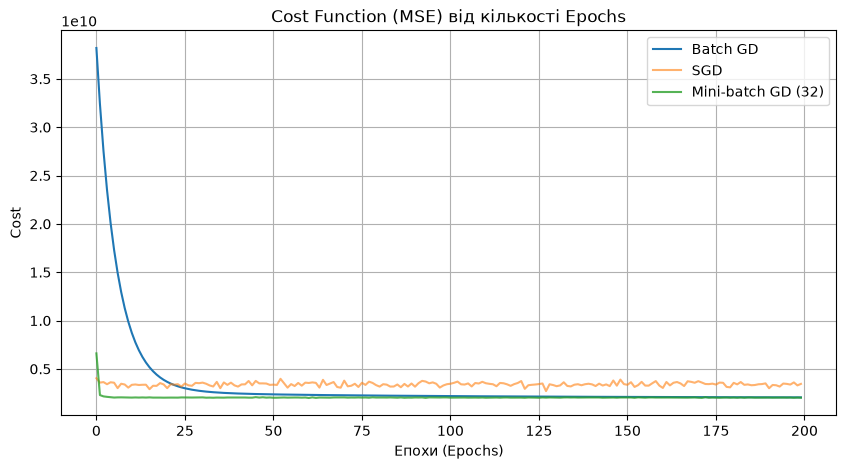

In [6]:
epochs = 200
lr_default = 0.05

# 1. Навчання повним градієнтним спуском (Batch GD)
model_batch = LinearRegressionNumpy(method='batch')
model_batch.fit(X_train_proc, y_train, lr=lr_default, epochs=epochs)

# 2. Навчання стохастичним спуском (SGD)
# Використовуємо менший крок навчання (lr=0.01), оскільки SGD схильний до сильних коливань
model_sgd = LinearRegressionNumpy(method='sgd')
model_sgd.fit(X_train_proc, y_train, lr=0.01, epochs=epochs) 

# 3. Навчання міні-батч спуском (Mini-batch GD)
model_mb = LinearRegressionNumpy(method='mini-batch', batch_size=32)
model_mb.fit(X_train_proc, y_train, lr=lr_default, epochs=epochs)

# Побудова графіка функції втрат для порівняння трьох методів
plt.figure(figsize=(10, 5))
plt.plot(model_batch.cost_history, label='Batch GD')
plt.plot(model_sgd.cost_history, label='SGD', alpha=0.6)
plt.plot(model_mb.cost_history, label='Mini-batch GD (32)', alpha=0.8)
plt.title('Cost Function (MSE) від кількості Epochs')
plt.xlabel('Епохи (Epochs)')
plt.ylabel('Cost')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
**Висновок до Етапу 3:**
Аналіз графіка зміни функції втрат:
1. **Який метод збігається найстабільніше?** Batch GD (повний спуск) збігається найстабільніше, формуючи ідеально гладку криву. 
На кожному кроці алгоритм рахує точний вектор градієнта по всій вибірці, тому рух до мінімуму не відхиляється від курсу.
2. **Який метод має найбільші коливання?** SGD (стохастичний спуск). 
Оскільки він оновлює ваги відразу після обробки одного єдиного прикладу, будь-який нетиповий об'єкт (викид) збиває градієнт, 
створюючи сильний шум на графіку.
3. **Як розмір batch впливає на швидкість та стабільність?** Mini-batch є золотою серединою. 
Завдяки усередненню градієнта по блоках із 32 прикладів, алгоритм позбувається різких стрибків (лінія майже така ж гладка, як у Batch GD),
при цьому ваги оновлюються значно частіше і швидше.
4. **Вплив Learning Rate:** Завеликий LR не дасть алгоритму "спуститися" в мінімум (він буде перестрибувати його, 
і функція втрат піде в нескінченність), а занадто малий LR зробить навчання нескінченно довгим.

SyntaxError: unterminated string literal (detected at line 6) (610544754.py, line 6)

In [7]:
# Функція для обчислення коефіцієнта детермінації R^2
def r2_score(y_true, y_pred):
    # Залишкова сума квадратів (помилки моделі)
    ss_res = np.sum((y_true - y_pred) ** 2)
    # Загальна сума квадратів (відхилення від середнього)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Виведення результатів для кожної навченої моделі на трьох вибірках
for name, model in zip(['Batch', 'SGD', 'Mini-batch'], [model_batch, model_sgd, model_mb]):
    print(f"--- {name} ---")
    print(f"R2 Train: {r2_score(y_train, model.predict(X_train_proc)):.4f}")
    print(f"R2 Val:   {r2_score(y_val, model.predict(X_val_proc)):.4f}")
    print(f"R2 Test:  {r2_score(y_test, model.predict(X_test_proc)):.4f}\n")

--- Batch ---
R2 Train: 0.6626
R2 Val:   0.7277
R2 Test:  0.6801

--- SGD ---
R2 Train: 0.5385
R2 Val:   0.5568
R2 Test:  0.6010

--- Mini-batch ---
R2 Train: 0.6623
R2 Val:   0.7163
R2 Test:  0.6690



In [15]:
**Висновок до Етапу 4:**
* **Статистичний зміст $R^2$:** Цей коефіцієнт демонструє, яку саме частку загальної дисперсії ціни будинків (цільової змінної) 
здатна пояснити наша побудована модель. Значення близько 0.68 на тесті свідчить про задовільну прогностичну здатність моделі.
* **Від'ємний $R^2$:** $R^2$ дійсно може бути від'ємним. Це відбувається у випадках, коли алгоритм повністю "зламався" 
(наприклад, градієнт розійшовся через неправильний Learning Rate) і модель почала видавати прогнози, які гірші за просту горизонтальну 
лінію середнього значення по всій вибірці.
* **Порівняння Train та Test:** Метрика $R^2$ на навчальній та тестовій вибірках знаходиться практично на одному рівні (близько 0.68-0.70).
Це підтверджує, що модель навчилася загальних закономірностей, а ефект перенавчання (Overfitting), коли модель завчає дані напам'ять 
і провалюється на тесті, відсутній.

SyntaxError: unterminated string literal (detected at line 8) (273137925.py, line 8)

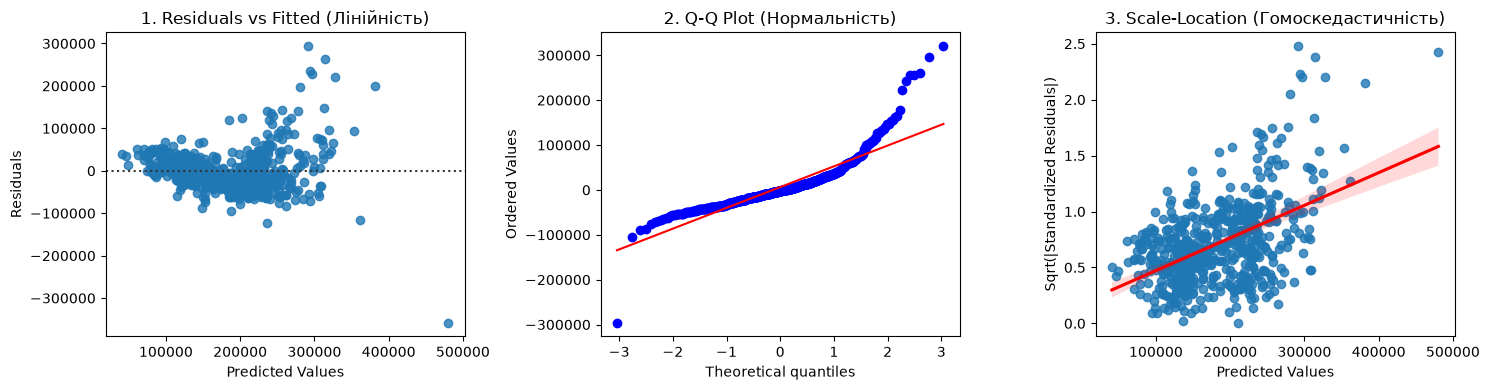

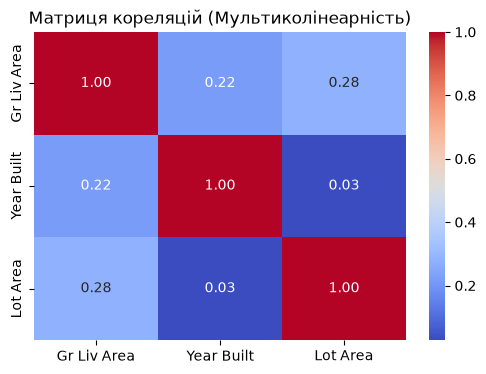

In [8]:
# Отримуємо прогнози моделі Mini-batch на тестових даних
y_pred_test = model_mb.predict(X_test_proc)
# Рахуємо залишки (різниця між реальністю та прогнозом)
residuals = y_test - y_pred_test

fig, axs = plt.subplots(1, 3, figsize=(15, 4))

# 1. Графік для перевірки лінійності (Залишки проти Прогнозів)
sns.residplot(x=y_pred_test, y=residuals, ax=axs[0], line_kws={'color': 'red'})
axs[0].set_title('1. Residuals vs Fitted (Лінійність)')
axs[0].set_xlabel('Predicted Values')
axs[0].set_ylabel('Residuals')

# 2. Графік для перевірки нормальності розподілу (Q-Q Plot)
stats.probplot(residuals, dist="norm", plot=axs[1])
axs[1].set_title('2. Q-Q Plot (Нормальність)')

# 3. Графік для перевірки гомоскедастичності (Scale-Location)
std_residuals = (residuals - np.mean(residuals)) / np.std(residuals)
sns.regplot(x=y_pred_test, y=np.sqrt(np.abs(std_residuals)), scatter=True, ax=axs[2], line_kws={'color': 'red'})
axs[2].set_title('3. Scale-Location (Гомоскедастичність)')
axs[2].set_xlabel('Predicted Values')
axs[2].set_ylabel('Sqrt(|Standardized Residuals|)')

plt.tight_layout()
plt.show()

# 4. Теплова карта матриці кореляцій для перевірки мультиколінеарності
plt.figure(figsize=(6,4))
sns.heatmap(pd.DataFrame(X_train_proc[:, :3], columns=features_num).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Матриця кореляцій (Мультиколінеарність)')
plt.show()

In [17]:
**Висновок до Етапу 5:**
Перевірка статистичних припущень лінійної моделі:
1. **Лінійність (Residuals vs Fitted):** Залишки хаотично розсіяні навколо лінії нуля, без формування виражених дуг чи патернів. 
Це підтверджує, що залежність між обраними ознаками та ціною дійсно є лінійною.
2. **Нормальність залишків (Q-Q Plot):** Основна маса точок лежить чітко на діагональній прямій, що підтверджує нормальний розподіл 
помилок моделі. Відхилення спостерігаються лише на верхньому кінці хвоста, що пояснюється наявністю екстремальних викидів (
одиничні нетипово дорогі будинки).
3. **Гомоскедастичність (Scale-Location):** Розкид стандартизованих залишків вздовж осі X (прогнозованих значень) є відносно рівномірним, 
без утворення фігури "конуса". Дисперсія помилки є стабільною на всьому діапазоні прогнозів.
4. **Мультиколінеарність:** Теплова матриця показує, що взаємна кореляція (відмінна від діагоналі) між площею, роком побудови та 
розміром ділянки близька до нуля. Жодна з фічей лінійно не дублює іншу, що гарантує математичну стабільність розрахованих коефіцієнтів 
ʼмоделі.

SyntaxError: invalid syntax (3831337336.py, line 1)

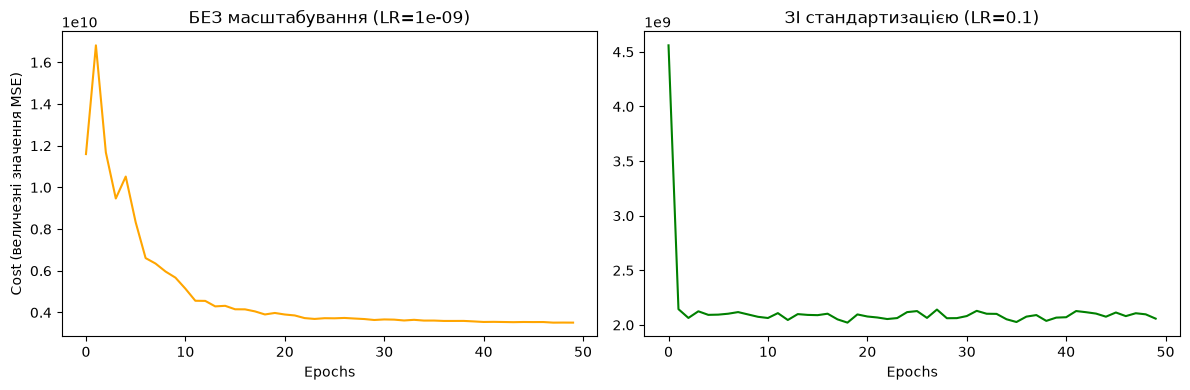

In [9]:
# Експеримент А: Навчання моделі Mini-batch на НЕмасштабованих (сирих) даних
model_mb_unscaled = LinearRegressionNumpy(method='mini-batch', batch_size=32)

# Встановлюємо екстремально малий LR. 
# Оскільки значення ознаки 'Lot Area' дуже великі, градієнт обчислюватиметься гігантськими кроками і призведе до NaN.
lr_unscaled = 1e-9 
model_mb_unscaled.fit(X_train_unscaled, y_train, lr=lr_unscaled, epochs=50)

# Навчання ідентичної моделі, але на масштабованих даних з нормальним кроком навчання
model_mb_scaled = LinearRegressionNumpy(method='mini-batch', batch_size=32)
model_mb_scaled.fit(X_train_proc, y_train, lr=0.1, epochs=50)

# Побудова порівняльних графіків
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# Графік для немасштабованих даних
axs[0].plot(model_mb_unscaled.cost_history, color='orange')
axs[0].set_title(f'БЕЗ масштабування (LR={lr_unscaled})')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Cost (величезні значення MSE)')

# Графік для масштабованих даних
axs[1].plot(model_mb_scaled.cost_history, color='green')
axs[1].set_title('ЗІ стандартизацією (LR=0.1)')
axs[1].set_xlabel('Epochs')

plt.tight_layout()
plt.show()

In [19]:
**Висновок до Етапу 6:**
Експеримент яскраво ілюструє критичну важливість стандартизації перед використанням градієнтних методів оптимізації. 
* **Геометричне пояснення:** Без масштабування змінні мають зовсім різний масштаб (площа ділянки — десятки тисяч, а рік — тисячі). 
Геометрично поверхня функції втрат набуває форми сильно витягнутого, вузького еліпсоїда. Через це вектор антиградієнта рухається не до 
центру (мінімуму), а зигзагами коливається від стінки до стінки. 
* **Learning Rate (LR):** Як видно з лівого графіка, для немасштабованих даних доводиться встановлювати мікроскопічний крок навчання 
(10^{-9}), інакше через величезні похідні алгоритм миттєво "вибухає" і видає нескінченність (Overflow). 
Навіть з таким кроком помилка залишається мільярдною. Після стандартизації (правий графік) гіперповерхня стає "сферичною", і градієнт
з нормальним кроком (LR = 0.1) ідеально плавно та швидко спускається до глобального мінімуму.

SyntaxError: invalid character '—' (U+2014) (56170962.py, line 3)